# How machines learn

A handful of classic learning algorithms, implemented with plain numpy and run on small synthetic datasets. Each one builds on the last: a linear model, a tree that adapts to the data, an ensemble that averages many trees, and a short experiment on how tree depth trades bias for variance.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

## The dataset

A 1D input `x` and a target `y = f(x) + noise`, where `f` mixes a smooth curve with a jump. Linear regression will struggle with the jump; tree-based methods will not.

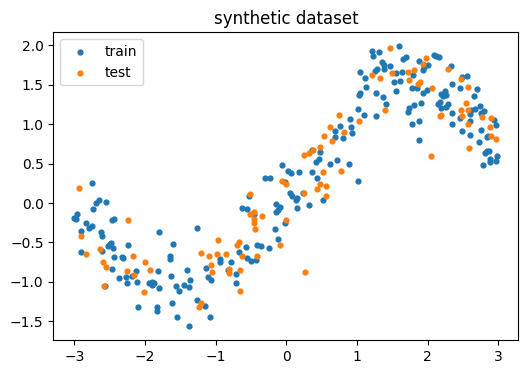

In [2]:
def make_dataset(n=300, noise=0.3, seed=0):
    rng = np.random.default_rng(seed)
    x = rng.uniform(-3, 3, n)
    y = np.sin(x) + 0.6 * (x > 1) + noise * rng.standard_normal(n)
    return x, y

def split(x, y, test_frac=0.3, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(x))
    cut = int(len(x) * test_frac)
    test, train = idx[:cut], idx[cut:]
    return x[train], y[train], x[test], y[test]

x, y = make_dataset()
x_train, y_train, x_test, y_test = split(x, y)

plt.figure(figsize=(6, 4))
plt.scatter(x_train, y_train, s=12, label="train")
plt.scatter(x_test, y_test, s=12, label="test")
plt.legend()
plt.title("synthetic dataset")
plt.show()

## Linear regression

Fit `y = a*x + b` by least squares. It picks up the overall trend but can't bend for the jump around `x = 1`.

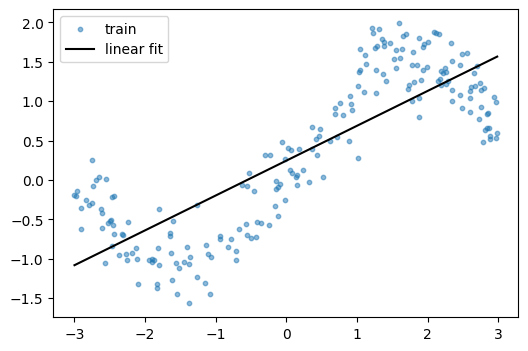

test RMSE: 0.5139162486335567


In [3]:
class LinearRegression:
    def fit(self, x, y):
        A = np.column_stack([x, np.ones_like(x)])
        self.coef_, *_ = np.linalg.lstsq(A, y, rcond=None)
        return self

    def predict(self, x):
        A = np.column_stack([x, np.ones_like(x)])
        return A @ self.coef_

lin = LinearRegression().fit(x_train, y_train)
grid = np.linspace(x.min(), x.max(), 200)

plt.figure(figsize=(6, 4))
plt.scatter(x_train, y_train, s=10, alpha=0.5, label="train")
plt.plot(grid, lin.predict(grid), color="black", label="linear fit")
plt.legend()
plt.show()

print("test RMSE:", rmse(y_test, lin.predict(x_test)))

## Decision tree regressor

Splits the input space in half repeatedly, each time on whichever feature correlates most with the target, at the median value of that feature. A leaf predicts the mean of the targets that land in it. Splitting stops once a node holds `leaf_size` or fewer points.

With multiple input features this correlation step decides which feature to split on; here there's only one feature, so the tree just decides where along `x` to cut.

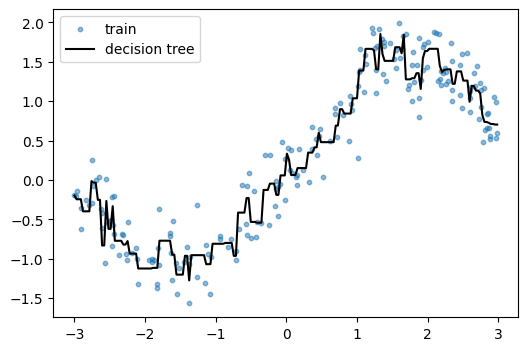

test RMSE: 0.3494747971696342


In [4]:
class DecisionTree:
    def __init__(self, leaf_size=1):
        self.leaf_size = leaf_size

    def fit(self, X, y):
        X = self._as_2d(X)
        self.tree_ = self._build(X, y)
        return self

    @staticmethod
    def _as_2d(X):
        return X.reshape(-1, 1) if X.ndim == 1 else X

    def _build(self, X, y):
        n, d = X.shape
        if n <= self.leaf_size or np.all(y == y[0]):
            return {"leaf": True, "value": y.mean()}

        best_feat, best_corr = 0, -1.0
        for f in range(d):
            col = X[:, f]
            if np.std(col) == 0:
                continue
            corr = np.corrcoef(col, y)[0, 1]
            corr = 0.0 if np.isnan(corr) else abs(corr)
            if corr > best_corr:
                best_feat, best_corr = f, corr

        split_val = np.median(X[:, best_feat])
        left = X[:, best_feat] <= split_val
        if left.all() or (~left).all():
            return {"leaf": True, "value": y.mean()}

        return {
            "leaf": False,
            "feature": best_feat,
            "split": split_val,
            "left": self._build(X[left], y[left]),
            "right": self._build(X[~left], y[~left]),
        }

    def _predict_row(self, node, row):
        while not node["leaf"]:
            node = node["left"] if row[node["feature"]] <= node["split"] else node["right"]
        return node["value"]

    def predict(self, X):
        X = self._as_2d(X)
        return np.array([self._predict_row(self.tree_, row) for row in X])

tree = DecisionTree(leaf_size=3).fit(x_train, y_train)

plt.figure(figsize=(6, 4))
plt.scatter(x_train, y_train, s=10, alpha=0.5, label="train")
plt.plot(grid, tree.predict(grid), color="black", label="decision tree")
plt.legend()
plt.show()

print("test RMSE:", rmse(y_test, tree.predict(x_test)))

## Random tree regressor

Same recursive structure, but each split picks a random feature and a random cut point between two randomly chosen rows, instead of searching for the best one. Cheaper to build, and on its own noisier than the decision tree above — it's meant to be used inside an ensemble, not alone.

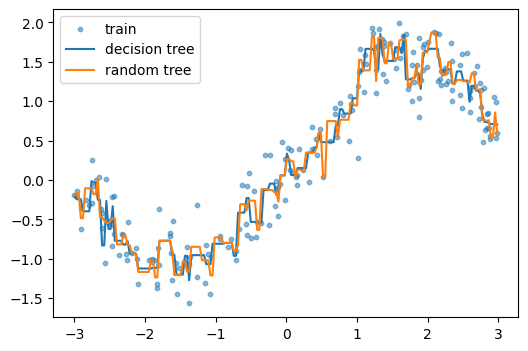

decision tree test RMSE: 0.3494747971696342
random tree test RMSE:   0.35916063273686466


In [5]:
class RandomTree(DecisionTree):
    def __init__(self, leaf_size=1, seed=None):
        super().__init__(leaf_size)
        self.rng = np.random.default_rng(seed)

    def _build(self, X, y):
        n, d = X.shape
        if n <= self.leaf_size or np.all(y == y[0]):
            return {"leaf": True, "value": y.mean()}

        feat = self.rng.integers(d)
        i, j = self.rng.choice(n, size=2, replace=False)
        split_val = (X[i, feat] + X[j, feat]) / 2
        left = X[:, feat] <= split_val
        if left.all() or (~left).all():
            return {"leaf": True, "value": y.mean()}

        return {
            "leaf": False,
            "feature": feat,
            "split": split_val,
            "left": self._build(X[left], y[left]),
            "right": self._build(X[~left], y[~left]),
        }

rtree = RandomTree(leaf_size=3, seed=1).fit(x_train, y_train)

plt.figure(figsize=(6, 4))
plt.scatter(x_train, y_train, s=10, alpha=0.5, label="train")
plt.plot(grid, tree.predict(grid), label="decision tree")
plt.plot(grid, rtree.predict(grid), label="random tree")
plt.legend()
plt.show()

print("decision tree test RMSE:", rmse(y_test, tree.predict(x_test)))
print("random tree test RMSE:  ", rmse(y_test, rtree.predict(x_test)))

## Bagging

Train many copies of a learner, each on a random sample of the training rows drawn with replacement (a "bootstrap" sample), then average their predictions. A single random tree with `leaf_size=1` memorizes noise; twenty of them, bootstrapped and averaged, smooth it out.

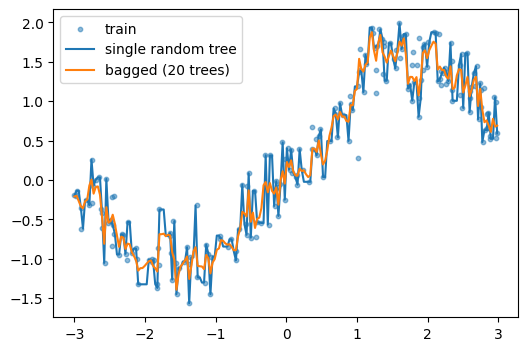

single tree test RMSE: 0.39663212211863746
bagged test RMSE:      0.34231538699339126


In [6]:
class BagLearner:
    def __init__(self, learner_cls, n_bags=20, learner_kwargs=None, seed=0):
        self.learner_cls = learner_cls
        self.n_bags = n_bags
        self.learner_kwargs = learner_kwargs or {}
        self.rng = np.random.default_rng(seed)

    def fit(self, X, y):
        X = DecisionTree._as_2d(np.asarray(X))
        n = len(X)
        self.learners_ = []
        for _ in range(self.n_bags):
            idx = self.rng.integers(0, n, n)
            learner = self.learner_cls(**self.learner_kwargs).fit(X[idx], y[idx])
            self.learners_.append(learner)
        return self

    def predict(self, X):
        preds = np.array([learner.predict(X) for learner in self.learners_])
        return preds.mean(axis=0)

single = RandomTree(leaf_size=1, seed=2).fit(x_train, y_train)
bagged = BagLearner(RandomTree, n_bags=20, learner_kwargs={"leaf_size": 1}, seed=2).fit(x_train, y_train)

plt.figure(figsize=(6, 4))
plt.scatter(x_train, y_train, s=10, alpha=0.5, label="train")
plt.plot(grid, single.predict(grid), label="single random tree")
plt.plot(grid, bagged.predict(grid), label="bagged (20 trees)")
plt.legend()
plt.show()

print("single tree test RMSE:", rmse(y_test, single.predict(x_test)))
print("bagged test RMSE:     ", rmse(y_test, bagged.predict(x_test)))

## Bagging a stable learner

Bagging reduces variance, so it only helps learners whose predictions swing a lot from one training sample to the next. Linear regression already gives close to the same line for any bootstrap sample of this data, so wrapping it in `BagLearner` barely moves the result — the gap comes from bias, and averaging more copies of the same line doesn't fix that.

In [7]:
class EnsembleOfBags:
    def __init__(self, learner_cls, n_ensembles=5, n_bags=10, learner_kwargs=None, seed=0):
        self.bags = [
            BagLearner(learner_cls, n_bags=n_bags, learner_kwargs=learner_kwargs, seed=seed + i)
            for i in range(n_ensembles)
        ]

    def fit(self, X, y):
        for bag in self.bags:
            bag.fit(X, y)
        return self

    def predict(self, X):
        return np.mean([bag.predict(X) for bag in self.bags], axis=0)

plain_scores, ensemble_scores = [], []
for seed in range(5):
    xs, ys = make_dataset(seed=seed)
    xr_train, yr_train, xr_test, yr_test = split(xs, ys, seed=seed)

    plain = LinearRegression().fit(xr_train, yr_train)
    ensemble = EnsembleOfBags(LinearRegression, seed=seed).fit(xr_train, yr_train)

    plain_scores.append(rmse(yr_test, plain.predict(xr_test)))
    ensemble_scores.append(rmse(yr_test, ensemble.predict(xr_test)))

print("plain linear regression RMSE across 5 datasets:", np.round(plain_scores, 3))
print("ensemble-of-bags RMSE across 5 datasets:        ", np.round(ensemble_scores, 3))

plain linear regression RMSE across 5 datasets: [0.514 0.542 0.578 0.537 0.579]
ensemble-of-bags RMSE across 5 datasets:         [0.513 0.542 0.578 0.538 0.576]


## Overfitting versus leaf size

Shrinking `leaf_size` lets the decision tree fit training points almost exactly, at the cost of doing worse on new data. Sweeping `leaf_size` and tracking in-sample and out-of-sample error separately shows the split clearly. Bagging the same tree at every `leaf_size` flattens most of that gap.

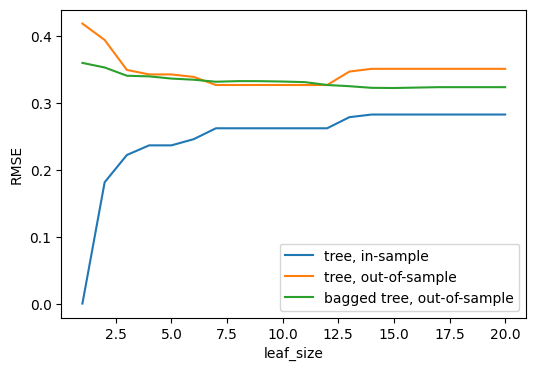

In [8]:
leaf_sizes = range(1, 21)
in_sample, out_sample, bagged_out_sample = [], [], []

for ls in leaf_sizes:
    t = DecisionTree(leaf_size=ls).fit(x_train, y_train)
    in_sample.append(rmse(y_train, t.predict(x_train)))
    out_sample.append(rmse(y_test, t.predict(x_test)))

    b = BagLearner(DecisionTree, n_bags=20, learner_kwargs={"leaf_size": ls}, seed=3).fit(x_train, y_train)
    bagged_out_sample.append(rmse(y_test, b.predict(x_test)))

plt.figure(figsize=(6, 4))
plt.plot(leaf_sizes, in_sample, label="tree, in-sample")
plt.plot(leaf_sizes, out_sample, label="tree, out-of-sample")
plt.plot(leaf_sizes, bagged_out_sample, label="bagged tree, out-of-sample")
plt.xlabel("leaf_size")
plt.ylabel("RMSE")
plt.legend()
plt.show()

## A classification dataset

Everything so far predicted a number. Classification predicts a label. Two Gaussian-ish clusters in 2D, close enough together that the classes overlap a little at the boundary — this is the dataset for every classifier below, so their decision boundaries can be compared directly.

In [9]:
def make_blobs(n=200, seed=0):
    rng = np.random.default_rng(seed)
    n0, n1 = n // 2, n - n // 2
    class0 = rng.normal(loc=[-1.2, -1.2], scale=1.1, size=(n0, 2))
    class1 = rng.normal(loc=[1.6, 1.6], scale=1.1, size=(n1, 2))
    X = np.vstack([class0, class1])
    y = np.concatenate([np.zeros(n0), np.ones(n1)])
    return X, y

def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)

def plot_boundary(predict_fn, X, y, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
    zz = predict_fn(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)

    plt.figure(figsize=(5, 4))
    plt.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], alpha=0.3, colors=["#1f77b4", "#ff7f0e"])
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=20)
    plt.title(title)
    plt.show()

X_cls, y_cls = make_blobs()
Xc_train, yc_train, Xc_test, yc_test = split(X_cls, y_cls)

## kNN classifier

No training step at all — it just remembers the data. To classify a new point, find its `k` nearest neighbors by distance and take a majority vote among their labels.

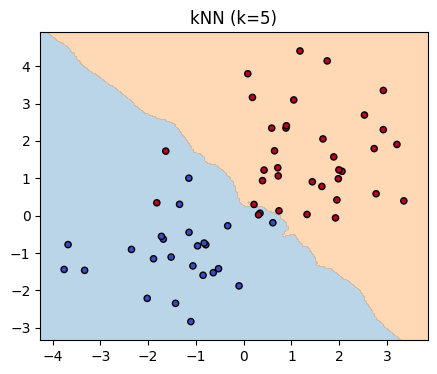

test accuracy: 0.95


In [10]:
class KNNClassifier:
    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):
        self.X_, self.y_ = X, y
        return self

    def predict(self, X):
        preds = np.empty(len(X))
        for i, row in enumerate(X):
            dists = np.linalg.norm(self.X_ - row, axis=1)
            nearest = self.y_[np.argsort(dists)[: self.k]]
            preds[i] = np.round(nearest.mean())
        return preds

knn = KNNClassifier(k=5).fit(Xc_train, yc_train)
plot_boundary(knn.predict, Xc_test, yc_test, "kNN (k=5)")
print("test accuracy:", accuracy(yc_test, knn.predict(Xc_test)))

## Logistic regression

Fits a straight decision boundary by gradient descent on the cross-entropy loss: pass the linear score through a sigmoid to get a probability, then nudge the weights to make that probability match the true label. It can only ever draw a straight line, which matters once the classes stop being linearly separable.

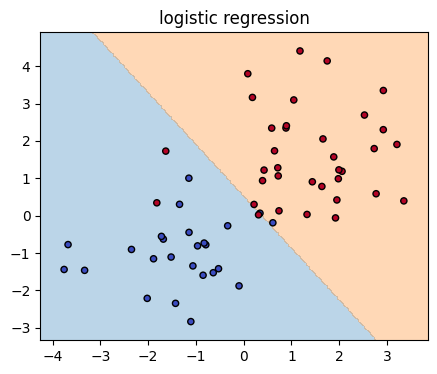

test accuracy: 0.9166666666666666


In [11]:
class LogisticRegression:
    def __init__(self, lr=0.1, epochs=500):
        self.lr = lr
        self.epochs = epochs

    def fit(self, X, y):
        n, d = X.shape
        Xb = np.column_stack([X, np.ones(n)])
        self.coef_ = np.zeros(d + 1)
        for _ in range(self.epochs):
            p = 1 / (1 + np.exp(-(Xb @ self.coef_)))
            self.coef_ -= self.lr * (Xb.T @ (p - y) / n)
        return self

    def predict_proba(self, X):
        Xb = np.column_stack([X, np.ones(len(X))])
        return 1 / (1 + np.exp(-(Xb @ self.coef_)))

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(float)

logreg = LogisticRegression().fit(Xc_train, yc_train)
plot_boundary(logreg.predict, Xc_test, yc_test, "logistic regression")
print("test accuracy:", accuracy(yc_test, logreg.predict(Xc_test)))

## Decision tree classifier

Same recursive splitting as the regression tree earlier, adapted for labels: at each node, split whichever feature reduces Gini impurity the most (at its median value), and stop once a node is pure or small enough. A leaf predicts its majority class instead of a mean.

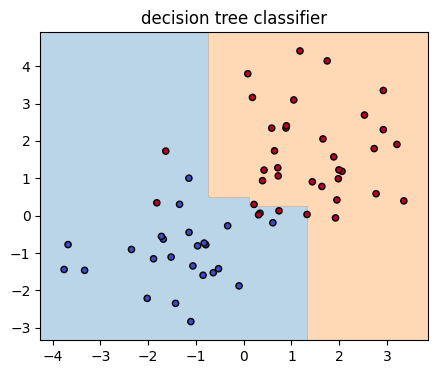

test accuracy: 0.9166666666666666


In [12]:
def gini(y):
    if len(y) == 0:
        return 0.0
    p = y.mean()
    return 1 - p ** 2 - (1 - p) ** 2

class DecisionTreeClassifier:
    def __init__(self, leaf_size=5):
        self.leaf_size = leaf_size

    def fit(self, X, y):
        self.tree_ = self._build(X, y)
        return self

    def _build(self, X, y):
        n, d = X.shape
        if n <= self.leaf_size or np.all(y == y[0]):
            return {"leaf": True, "value": np.round(y.mean())}

        parent = gini(y)
        best_feat, best_gain, best_split = 0, -1.0, np.median(X[:, 0])
        for f in range(d):
            split_val = np.median(X[:, f])
            left = X[:, f] <= split_val
            if left.all() or (~left).all():
                continue
            gain = parent - (left.mean() * gini(y[left]) + (~left).mean() * gini(y[~left]))
            if gain > best_gain:
                best_feat, best_gain, best_split = f, gain, split_val

        if best_gain <= 0:
            return {"leaf": True, "value": np.round(y.mean())}

        left = X[:, best_feat] <= best_split
        return {
            "leaf": False,
            "feature": best_feat,
            "split": best_split,
            "left": self._build(X[left], y[left]),
            "right": self._build(X[~left], y[~left]),
        }

    def _predict_row(self, node, row):
        while not node["leaf"]:
            node = node["left"] if row[node["feature"]] <= node["split"] else node["right"]
        return node["value"]

    def predict(self, X):
        return np.array([self._predict_row(self.tree_, row) for row in X])

dtc = DecisionTreeClassifier(leaf_size=5).fit(Xc_train, yc_train)
plot_boundary(dtc.predict, Xc_test, yc_test, "decision tree classifier")
print("test accuracy:", accuracy(yc_test, dtc.predict(Xc_test)))

## Random forest

Two ideas stacked on top of the classifier tree: bag over bootstrap samples like before, and at every split let each tree see only a random subset of the features rather than all of them. With two features that means each split is forced to pick one or the other at random before choosing the best cut — this is what decorrelates the trees enough for averaging to help. Since labels are 0/1, the existing `BagLearner` already does the right thing: its average across trees is the fraction voting class 1, and thresholding that at 0.5 is a majority vote.

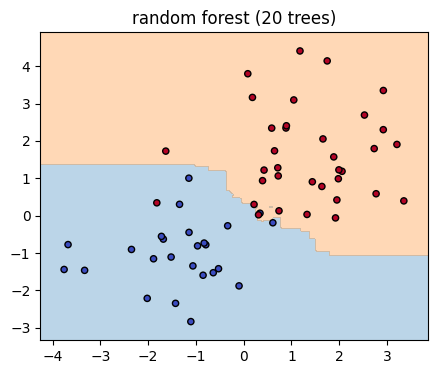

single tree test accuracy: 0.9166666666666666
forest test accuracy:      0.9666666666666667


In [13]:
class RandomForestTree(DecisionTreeClassifier):
    def __init__(self, leaf_size=5, n_features=1, seed=None):
        super().__init__(leaf_size)
        self.n_features = n_features
        self.rng = np.random.default_rng(seed)

    def _build(self, X, y):
        n, d = X.shape
        if n <= self.leaf_size or np.all(y == y[0]):
            return {"leaf": True, "value": np.round(y.mean())}

        parent = gini(y)
        candidates = self.rng.choice(d, size=min(self.n_features, d), replace=False)
        best_feat, best_gain, best_split = candidates[0], -1.0, np.median(X[:, candidates[0]])
        for f in candidates:
            split_val = np.median(X[:, f])
            left = X[:, f] <= split_val
            if left.all() or (~left).all():
                continue
            gain = parent - (left.mean() * gini(y[left]) + (~left).mean() * gini(y[~left]))
            if gain > best_gain:
                best_feat, best_gain, best_split = f, gain, split_val

        if best_gain <= 0:
            return {"leaf": True, "value": np.round(y.mean())}

        left = X[:, best_feat] <= best_split
        return {
            "leaf": False,
            "feature": best_feat,
            "split": best_split,
            "left": self._build(X[left], y[left]),
            "right": self._build(X[~left], y[~left]),
        }

single_rf_tree = RandomForestTree(leaf_size=5, n_features=1, seed=0).fit(Xc_train, yc_train)
forest = BagLearner(RandomForestTree, n_bags=20, learner_kwargs={"leaf_size": 5, "n_features": 1}, seed=0)
forest.fit(Xc_train, yc_train)
forest_predict = lambda X: (forest.predict(X) >= 0.5).astype(float)

plot_boundary(forest_predict, Xc_test, yc_test, "random forest (20 trees)")
print("single tree test accuracy:", accuracy(yc_test, single_rf_tree.predict(Xc_test)))
print("forest test accuracy:     ", accuracy(yc_test, forest_predict(Xc_test)))

## Naive Bayes

Assumes the two features are independent given the class, and models each one as Gaussian. Fitting means computing a mean, variance, and prior for each class; predicting means scoring each class by its log-likelihood and picking the larger one. No iterative optimization anywhere.

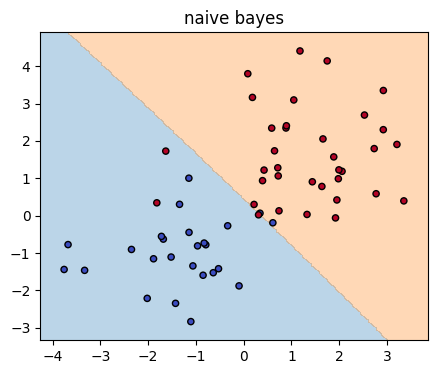

test accuracy: 0.9166666666666666


In [14]:
class GaussianNB:
    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.priors_, self.means_, self.vars_ = {}, {}, {}
        for c in self.classes_:
            Xc = X[y == c]
            self.priors_[c] = len(Xc) / len(X)
            self.means_[c] = Xc.mean(axis=0)
            self.vars_[c] = Xc.var(axis=0) + 1e-6
        return self

    def _log_likelihood(self, X, c):
        mean, var = self.means_[c], self.vars_[c]
        return -0.5 * np.sum(np.log(2 * np.pi * var)) - 0.5 * np.sum((X - mean) ** 2 / var, axis=1)

    def predict(self, X):
        scores = np.column_stack(
            [np.log(self.priors_[c]) + self._log_likelihood(X, c) for c in self.classes_]
        )
        return self.classes_[np.argmax(scores, axis=1)]

nb_model = GaussianNB().fit(Xc_train, yc_train)
plot_boundary(nb_model.predict, Xc_test, yc_test, "naive bayes")
print("test accuracy:", accuracy(yc_test, nb_model.predict(Xc_test)))

## Boosting: AdaBoost

Bagging trains many learners independently on resampled data to cut down variance. Boosting does the opposite: it trains learners one after another on the *same* data, but reweights the points after each round so the next learner focuses on whatever the previous ones got wrong. Each weak learner here is a decision stump — a tree with a single split — and the final prediction is a weighted vote across all of them, weighted by how accurate each stump was.

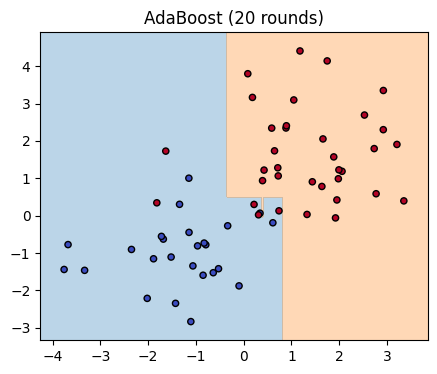

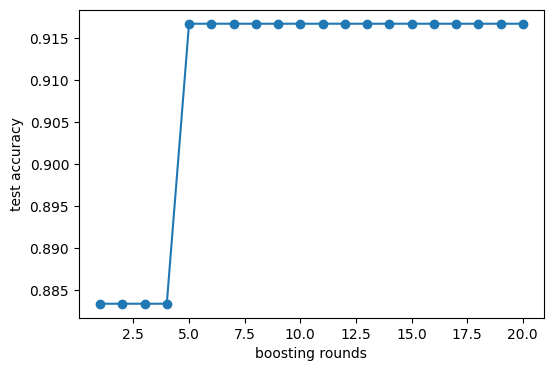

In [15]:
class DecisionStump:
    def fit(self, X, y, weights):
        n, d = X.shape
        best = (0, 0.0, 1, np.inf)  # feature, split, polarity, weighted error
        for f in range(d):
            for t in np.unique(X[:, f]):
                for polarity in (1, -1):
                    pred = np.where(polarity * X[:, f] <= polarity * t, 1, -1)
                    err = weights[pred != y].sum()
                    if err < best[3]:
                        best = (f, t, polarity, err)
        self.feature, self.split, self.polarity, _ = best
        return self

    def predict(self, X):
        return np.where(self.polarity * X[:, self.feature] <= self.polarity * self.split, 1, -1)

class AdaBoost:
    def __init__(self, n_rounds=20):
        self.n_rounds = n_rounds

    def fit(self, X, y):
        y_pm = np.where(y == 1, 1, -1)
        weights = np.full(len(X), 1 / len(X))
        self.stumps_, self.alphas_ = [], []
        for _ in range(self.n_rounds):
            stump = DecisionStump().fit(X, y_pm, weights)
            pred = stump.predict(X)
            err = np.clip(weights[pred != y_pm].sum(), 1e-10, 1 - 1e-10)
            alpha = 0.5 * np.log((1 - err) / err)
            weights *= np.exp(-alpha * y_pm * pred)
            weights /= weights.sum()
            self.stumps_.append(stump)
            self.alphas_.append(alpha)
        return self

    def predict(self, X, n_rounds=None):
        n_rounds = len(self.stumps_) if n_rounds is None else n_rounds
        agg = sum(a * s.predict(X) for a, s in zip(self.alphas_[:n_rounds], self.stumps_[:n_rounds]))
        return np.where(agg >= 0, 1.0, 0.0)

ada = AdaBoost(n_rounds=20).fit(Xc_train, yc_train)
plot_boundary(ada.predict, Xc_test, yc_test, "AdaBoost (20 rounds)")

rounds = range(1, 21)
accs = [accuracy(yc_test, ada.predict(Xc_test, n_rounds=r)) for r in rounds]
plt.figure(figsize=(6, 4))
plt.plot(rounds, accs, marker="o")
plt.xlabel("boosting rounds")
plt.ylabel("test accuracy")
plt.show()

## k-Means clustering

Everything above learned to predict `y` from `x`. Clustering drops the target entirely and just looks for structure in the points themselves. Treating each `(x, y)` pair as a 2D point: pick `k` centroids, assign every point to its nearest one, move each centroid to the mean of its assigned points, and repeat until nothing moves. There's no "correct" cluster here — this is just the mechanism, run on data that wasn't built with clusters in mind.

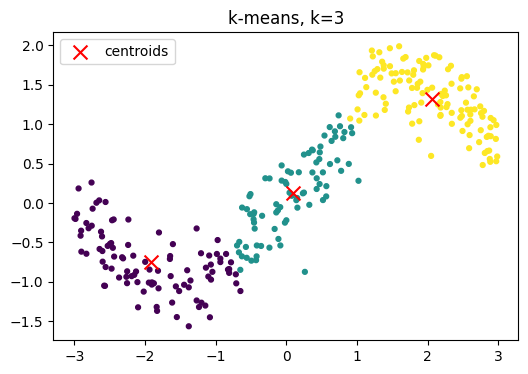

In [16]:
class KMeans:
    def __init__(self, k=3, max_iter=100, seed=0):
        self.k = k
        self.max_iter = max_iter
        self.rng = np.random.default_rng(seed)

    def fit(self, X):
        init = self.rng.choice(len(X), self.k, replace=False)
        self.centroids_ = X[init].copy()
        for _ in range(self.max_iter):
            dists = np.linalg.norm(X[:, None, :] - self.centroids_[None, :, :], axis=2)
            labels = dists.argmin(axis=1)
            new_centroids = np.array([
                X[labels == j].mean(axis=0) if np.any(labels == j) else self.centroids_[j]
                for j in range(self.k)
            ])
            if np.allclose(new_centroids, self.centroids_):
                break
            self.centroids_ = new_centroids
        self.labels_ = labels
        self.inertia_ = ((X - self.centroids_[labels]) ** 2).sum()
        return self

points = np.column_stack([x, y])
km = KMeans(k=3, seed=0).fit(points)

plt.figure(figsize=(6, 4))
plt.scatter(points[:, 0], points[:, 1], c=km.labels_, cmap="viridis", s=12)
plt.scatter(km.centroids_[:, 0], km.centroids_[:, 1], c="red", marker="x", s=100, label="centroids")
plt.legend()
plt.title("k-means, k=3")
plt.show()

`k` has to be chosen up front, and nothing in the algorithm says what it should be. One way to narrow it down: fit for a range of `k` values and plot inertia (total squared distance from each point to its centroid), which always decreases as `k` grows. The point where it stops dropping quickly is a reasonable place to stop.

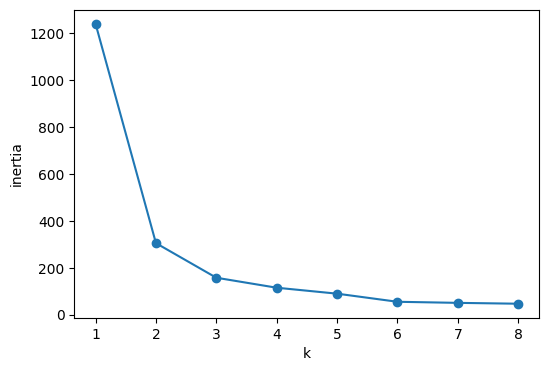

In [17]:
ks = range(1, 9)
inertias = [KMeans(k=k, seed=0).fit(points).inertia_ for k in ks]

plt.figure(figsize=(6, 4))
plt.plot(ks, inertias, marker="o")
plt.xlabel("k")
plt.ylabel("inertia")
plt.show()

## PCA

k-Means groups points; PCA finds directions. Center the data, take the covariance matrix, and its eigenvectors point along the axes of greatest spread — the first eigenvector is the single direction that preserves the most information if everything else gets dropped.

variance explained by each component: [0.811 0.189]


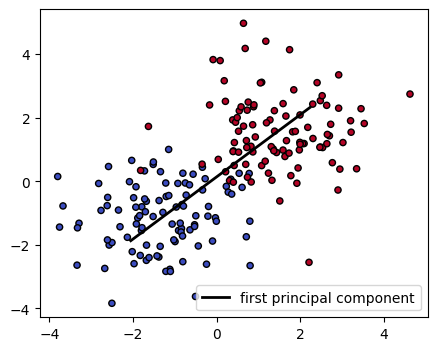

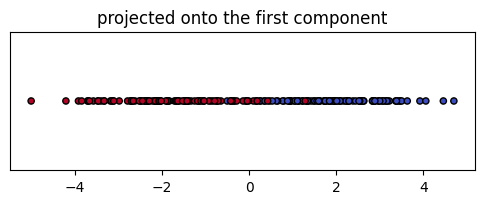

In [18]:
def pca(X):
    Xc = X - X.mean(axis=0)
    eigvals, eigvecs = np.linalg.eigh(np.cov(Xc, rowvar=False))
    order = np.argsort(eigvals)[::-1]
    return eigvals[order], eigvecs[:, order], Xc

eigvals, eigvecs, Xc_centered = pca(X_cls)
print("variance explained by each component:", np.round(eigvals / eigvals.sum(), 3))

pc1 = eigvecs[:, 0]
mean = X_cls.mean(axis=0)
span = np.array([mean - 3 * pc1, mean + 3 * pc1])

plt.figure(figsize=(5, 4))
plt.scatter(X_cls[:, 0], X_cls[:, 1], c=y_cls, cmap="coolwarm", edgecolor="k", s=20)
plt.plot(span[:, 0], span[:, 1], color="black", linewidth=2, label="first principal component")
plt.legend()
plt.show()

projected = Xc_centered @ pc1
plt.figure(figsize=(6, 1.8))
plt.scatter(projected, np.zeros_like(projected), c=y_cls, cmap="coolwarm", edgecolor="k", s=20)
plt.yticks([])
plt.title("projected onto the first component")
plt.show()

# Summary

Linear regression is stable but can only draw a straight line. A decision tree can match any shape but overfits when leaves get small. Random trees trade split quality for speed and diversity, which is what makes them useful inside an ensemble. Bagging turns a handful of overfit, high-variance trees into one that generalizes better, but does nothing for a learner like linear regression whose error was never about variance to begin with.

The classification side mirrors this: logistic regression draws one straight boundary, kNN and the decision tree bend to fit the data directly, naive Bayes gets there with no iteration at all by assuming independence, and random forest applies the same bagging idea to classification trees. Boosting takes the opposite approach from bagging — training learners one after another on reweighted data to fix what came before, trading variance reduction for bias reduction.

k-means and PCA both work without any labels at all. k-means answers "how does this data group on its own," PCA answers "which directions carry the most spread" — clustering versus finding structure along axes, rather than clustering versus predicting a target.